# Which Power Projects Actually Get Built?
## Development Risk in the Middle East and Beyond

*ENSAE Paris, Python for Data Science, 2026-2027*
*Sylvain Topeza, Maxime Rolland, Arcadius Kouwagou*

---

**Summary.** Governments and companies announce far more power plants than they build.
Using Global Energy Monitor's asset-level data on about 180,000 power units worldwide,
enriched with World Bank country data, we measure how much announced capacity is
abandoned rather than built, and what explains the difference.

Three findings stand out:

1. **About 40% of the capacity that reached an outcome was abandoned rather than built**
   (between 32% and 48% depending on the definition). The rate ranges from 20% for solar
   to 57% for coal and 75% for nuclear.
2. **Development risk depends heavily on the market.** Gulf countries abandon far less
   than the rest of the world (14% against 41%), with Saudi Arabia and Qatar close to zero.
   The relationship with the quality of regulation is U-shaped: rates are highest both in
   fragile countries and in rich, open markets such as the United Kingdom or Australia.
   What matters is who selects projects.
3. **The developer matters much less than the market.** Gulf developers abandon none of
   their projects at home but 34% abroad, close to their Western and Asian peers (40%).
   Controlling for technology, size and country, having a large international sponsor
   does not change the odds of abandonment.

**Contents**
1. Introduction
2. Data: collection and cleaning
3. A first look: what runs, what is built, what is announced
4. How much of what is announced gets built?
5. Where is development risk highest?
6. Is it the market or the developer?
7. Conclusion

**How to run this notebook.** Run all cells from top to bottom (about 2 minutes the first
time, while the raw data is downloaded and cached). The notebook runs on any computer with
Python 3.11+ and an internet connection. Setup instructions are in the
`README.md`. The code is organised in modules in `src/`; this notebook only calls them.

In [1]:
import warnings

import pandas as pd
from IPython.display import display

from src import clean, config, indicators, load, model, plots, worldbank

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

# 1. Introduction

### Announced projects and built projects

Energy news is full of announcements: a 5 GW solar park here, a new gas plant there,
national targets of tens of gigawatts. Many of these projects will never be built.
Permits are refused, financing falls through, a tender is cancelled, or a government
changes its priorities.

For anyone who finances or invests in infrastructure, this gap is central. A developer's
value depends on how much of its pipeline will actually reach construction. A government's
energy plan is only as credible as its ability to turn announcements into plants. This
uncertainty is called **development risk**: the risk that a project dies before it is built.

### Why the Middle East

The Middle East is a striking case for two reasons. First, the Gulf states buy electricity
through a single state-owned buyer, which runs tenders and signs long-term purchase
contracts with private developers. This model is very different from the open markets of
Europe or the United States, where developers propose projects and compete for permits,
grid connections and customers. Second, Gulf companies such as ACWA Power (Saudi Arabia) and
Masdar (Abu Dhabi) have become major international developers. Following the same companies
at home and abroad lets us ask whether development risk comes from the developer or from the
market it operates in.

### Problem statement

> **Which power projects actually get built, and why?**

We answer three questions:

1. **How much of what is announced gets built?** We measure abandonment rates worldwide and
   by technology.
2. **Where is development risk highest?** We compare countries, with a focus on the
   Middle East, and relate the results to country characteristics from the World Bank.
3. **Is it the market or the developer?** We compare Gulf developers at home and abroad,
   benchmark them against global peers (ENGIE, EDF, Ørsted, Brookfield, etc.) and estimate
   a logistic regression that separates technology, country and developer effects.

# 2. Data: collection and cleaning

### 2.1 Sources

| Source | Content | Collection |
|---|---|---|
| **Global Integrated Power Tracker**, Global Energy Monitor, September 2026 | One row per power unit (183,404 rows): technology, capacity, status, start year, owners, location | Excel file mirrored, unchanged, on a public URL of our SSP Cloud storage (CC BY 4.0), downloaded by the code |
| **World Bank API** | Income group, GDP per capita and Regulatory Quality (Worldwide Governance Indicators) for each country | Automated queries of the public API, with pagination |
| **ISO country codes** (datasets/country-codes, GitHub) | Country names and ISO codes | CSV read from a public URL; used to join the two sources above |
| **Sponsor dictionary** (`data/sponsors.csv`) | 30 companies, their name patterns and home country | Built by hand from public information |

Global Energy Monitor (GEM) is a non-profit that tracks energy infrastructure worldwide
from public sources: regulators, company reports, local press. The tracker covers power
plants above size thresholds that vary by technology and sometimes by country (for
instance, coal units from 30 MW; in this release, the smallest solar and wind units
listed are 1 MW). Its key feature for us is the **status** of each
unit: from *announced* to *operating*, including *cancelled* and *shelved* projects.
Abandoned projects are rarely kept in other databases, which only list plants that exist.

In [2]:
gem = load.load_gem()
print(f"{gem.shape[0]:,} power units, {gem.shape[1]} columns")

183,404 power units, 54 columns


### 2.2 A first look at the raw data

Each row is a **unit**: a generating unit of a plant or a phase of a solar or wind
project. A plant can therefore span several rows. The columns we use are shown below.

In [3]:
units_raw = clean.select_columns(gem)
display(units_raw.sample(5, random_state=config.RANDOM_SEED)
        .astype({"start_year": "Int64"}))

,unit_id,project,type,country,region,subregion,capacity_mw,status,start_year,owners,parents,latitude,longitude
182059,G100001053795,Purti Sugar power station,bioenergy,India,Asia,Southern Asia,24.00,operating,<NA>,<NA>,<NA>,20.80,79.06
159533,G100000110058,Thap Sakae power station,coal,Thailand,Asia,South-eastern Asia,800.00,cancelled,2025,Electricity Generating Authority of Thailand [...,Electricity Generating Authority of Thailand [...,11.50,99.62
114160,G100001005092,Jiangxi Chongyi Guantian wind farm,wind,China,Asia,Eastern Asia,50.00,pre-construction,<NA>,Jiangxi Datang International New Energy Co Ltd,<NA>,25.58,114.17
20520,G100001014547,Lianhua County Huida Industrial Lianhua County...,utility-scale solar,China,Asia,Eastern Asia,2.60,operating,2016,<NA>,<NA>,27.23,113.96
55089,G100000825957,Belpasso Catania solar farm I,utility-scale solar,Italy,Europe,Southern Europe,2.00,operating,<NA>,<NA>,<NA>,37.50,15.09


In [4]:
status_table = (
    units_raw
    .groupby("status")
    .agg(units=("unit_id", "count"), capacity_gw=("capacity_mw", "sum"))
    .assign(capacity_gw=lambda df: df["capacity_gw"] / 1000,
            share_of_capacity=lambda df: df["capacity_gw"] / df["capacity_gw"].sum())
    .sort_values("capacity_gw", ascending=False)
)
display(status_table.style.format(
    {"units": "{:,.0f}", "capacity_gw": "{:,.0f}", "share_of_capacity": "{:.1%}"}))

,units,capacity_gw,share_of_capacity
status,,,
operating,"128,100","8,719",38.5%
pre-construction,"21,923","3,598",15.9%
announced,"7,578","3,166",14.0%
cancelled,"7,209","2,827",12.5%
construction,"6,235","1,732",7.6%
cancelled - inferred 4 y,"2,989",758,3.3%
retired,"4,389",756,3.3%
shelved - inferred 2 y,"2,809",588,2.6%
shelved,"1,468",358,1.6%


The tracker lists about 22,600 GW of capacity. Operating plants account for 38% of it.
**Projects that are not yet built (announced, pre-construction, construction) total about
8,500 GW**, as much as the whole operating fleet. And about 4,500 GW of projects were
cancelled or shelved. This is the raw material of our question.

Two statuses need care. *Cancelled - inferred 4 y* and *shelved - inferred 2 y* mean that
GEM found no news of the project for four (or two) years and classified it as abandoned
without an official announcement. We treat them as abandoned, and check in section 4 that
our results hold without them.

In [5]:
missing = (
    units_raw.isna().mean()
    .rename("share_missing")
    .to_frame()
    .sort_values("share_missing", ascending=False)
)
display(missing.style.format("{:.1%}"))

,share_missing
parents,81.7%
owners,50.6%
start_year,29.7%
project,0.0%
unit_id,0.0%
region,0.0%
country,0.0%
type,0.0%
subregion,0.0%
status,0.0%


Missing values are concentrated in three columns:

- **Parent companies** (`parents`) are only reported for coal, gas and some other
  thermal plants, where GEM links each owner to its ultimate parent.
- **Owners** (`owners`) are missing for half of the units, but these are mostly small
  solar projects in Europe and Asia: owners are known for 89% of the capacity worldwide,
  and for over 90% of the capacity in the Middle East.
- **Start year** is missing for most projects that are not yet operating, which is
  expected: they have no start date yet. It is known for 90% of operating units.

These gaps shape our method: we cannot follow projects over time (no announcement date),
and our analysis of owners leaves out many small projects.

### 2.3 Cleaning the unit table

The function `clean.build_units` applies five steps, each in its own function:

1. **Select and rename** the useful columns (snake_case names).
2. **Group the ten statuses into four stages**: *pipeline* (announced and pre-construction),
   *construction*, *operating* and *abandoned* (cancelled and shelved, including inferred
   statuses). Retired and mothballed units go into *other*. The mapping is defined in
   `config.STATUS_TO_STAGE`; the function raises an error if GEM introduces a new status.
3. **Add readable labels**: technology names, and a regional grouping (GCC, rest of the
   Middle East, rest of the world).
4. **Add ISO country codes**, needed to join the World Bank data.
5. **Flag the units that reached an outcome** (defined in 2.4).

We also drop two units with a capacity of zero and check that unit identifiers are unique.

In [6]:
country_codes = load.load_country_codes()
units = clean.build_units(gem, country_codes)

stage_table = (
    units.groupby("stage")
    .agg(units=("unit_id", "count"), capacity_gw=("capacity_mw", "sum"))
    .assign(capacity_gw=lambda df: df["capacity_gw"] / 1000)
    .loc[["pipeline", "construction", "operating", "abandoned", "other"]]
)
display(stage_table.style.format({"units": "{:,.0f}", "capacity_gw": "{:,.0f}"}))

,units,capacity_gw
stage,,
pipeline,"29,500","6,764"
construction,"6,235","1,732"
operating,"128,100","8,719"
abandoned,"14,474","4,531"
other,"5,093",896


**Joining country codes.** GEM uses short English country names ("DR Congo", "Türkiye",
"United States"), which do not always match the names of the ISO reference table. We
match them first on the CLDR display names, then on the official names, and fix the 20
remaining cases by hand (`config.COUNTRY_NAME_FIXES`). The check below confirms that every
unit has a country code.

In [7]:
unmatched = units.loc[units["iso3"].isna(), "country"].unique()
print(f"Countries without an ISO code: {len(unmatched)}")
print(f"Countries in the data: {units['country'].nunique()}")

Countries without an ISO code: 0
Countries in the data: 226


### 2.4 Measuring development risk: the outcome sample

GEM gives no announcement date, so we cannot follow a cohort of projects from
announcement to completion. We use the following approach instead.

A project **reached an outcome** if it was either **abandoned** (cancelled or shelved) or
**built** (under construction, or in operation since 2010). Projects still in the pipeline
have no outcome yet, so they are left out. The **abandonment rate** of a group is then:

$$\text{abandonment rate} = \frac{\text{abandoned MW}}{\text{abandoned MW} + \text{built MW}}$$

Why only plants built since 2010? Including every operating plant, some built in the
1950s, would compare decades of successes with the much shorter list of failures that
public sources remember, and make the rate artificially low.

**This cut-off has a limit that we must state clearly: it applies to built projects only.**
Abandoned projects almost never have a date (only 3% do), so all of them enter the
calculation, whatever their era. Old cancellations are thus compared with recent
constructions. This inflates the rates of technologies with a long history of
cancellations: for instance, the 185 GW of abandoned nuclear capacity in the United States
largely date back to the 1970s and 1980s. The rates should therefore be read as orders of
magnitude, and comparisons between technologies with caution; comparisons between
countries and between developers, which mostly concern recent projects, are less affected.

A second choice is optimistic: projects under construction are counted as built, although
some will still be abandoned. Section 4 gives the rates without them.

Rates are **weighted by capacity**: a 2 GW project weighs a hundred times more than a 20 MW
one. This reflects what matters to a grid operator or an investor. Counted in units, the
rate would be only 12%, because most units are small solar farms that are rarely abandoned.

In [8]:
sample_share = units["in_outcome_sample"].mean()
print(f"Units in the outcome sample: {units['in_outcome_sample'].sum():,} "
      f"({sample_share:.0%} of all units)")

Units in the outcome sample: 116,296 (63% of all units)


### 2.5 Who owns what: parsing the ownership fields

Ownership is stored as text, with all owners of a unit in one cell, separated by
semicolons, and their share in brackets when known. The function `clean.parse_owners`
extracts each owner and its share with a regular expression:

In [9]:
example = "Saudi Electricity Co [50%]; ACWA Power Co [30%]; Korea Electric Power Corp [20%]"
clean.parse_owners(example)

[('Saudi Electricity Co', 50.0),
 ('ACWA Power Co', 30.0),
 ('Korea Electric Power Corp', 20.0)]

When no share is reported, capacity is split equally between owners; when only some
shares are reported, owners without a share get zero, so that the total never exceeds 100%.
We use the **ultimate parent** when GEM reports it (coal and gas plants), and the direct
owner otherwise. `clean.build_ownership` then turns the unit table into a **long table with
one row per unit and owner**, and computes each owner's **equity capacity** (capacity ×
share). The table below shows how often shares are actually reported.

In [10]:
ownership = clean.build_ownership(units)

coverage = (
    units.assign(has_owner=units["owners"].notna() | units["parents"].notna())
    .groupby("technology")
    .agg(units=("unit_id", "count"), share_with_owner=("has_owner", "mean"))
    .join(ownership.groupby("technology")["share_reported"].mean()
          .rename("share_of_owner_records_with_percentages"))
    .sort_values("units", ascending=False)
)
display(coverage.style.format({"units": "{:,.0f}", "share_with_owner": "{:.0%}",
                               "share_of_owner_records_with_percentages": "{:.0%}"}))

,units,share_with_owner,share_of_owner_records_with_percentages
technology,,,
Solar,"103,940",23%,75%
Wind,"35,089",70%,78%
Gas & oil,"15,201",99%,100%
Coal,"14,674",100%,100%
Hydropower,"7,023",87%,73%
Bioenergy,"4,815",81%,100%
Nuclear,"1,825",89%,97%
Geothermal,835,85%,66%


Owners are known for almost all thermal plants, but for only a quarter of solar units
(mostly small projects in Europe and Asia). When owners are listed, their shares are
reported in most cases: always for coal and gas, and for about three quarters of solar and
wind ownership records. The equal split is therefore used for a minority of records.

### 2.6 Grouping companies: the sponsor dictionary

A company appears under many names: subsidiaries, project companies, spelling variants.
To follow **30 large sponsors** (12 from the Gulf, 18 global peers), we wrote a dictionary
(`data/sponsors.csv`) with a regular expression per company, and its home country. Two
recent acquisitions not yet reflected in GEM are added by hand: Terna Energy (Greece) and
Saeta Yield (Spain), both bought by Masdar in 2024.

Checking the matches by eye was essential. Our first version contained several false
positives: the pattern *Nebras* (Qatar's power investor) also captured the **Nebraska**
Public Power District; *Neoen* captured **Neoenergia**, Iberdrola's Brazilian subsidiary;
*Mitsui* and *Sumitomo* captured unrelated banks, cement and real-estate companies. Nebras's
operating capacity abroad dropped from 5.3 GW to 1.4 GW once American utilities were removed.
The table below lists, for each group, the largest raw names it now captures.

In [11]:
sponsors = load.load_sponsors()
ownership = clean.assign_sponsor_groups(ownership, sponsors)
display(clean.matched_owner_names(ownership))

,sponsor_group,n_names,largest_names
0,ACWA Power,1,ACWA Power Co
1,AMEA Power,1,AMEA Power
2,Al Nowais,1,Al Nowais Investments LLC
3,Alfanar,2,Alfanar Group; Alfanar Energía España SL
4,Aljomaih,2,Aljomaih Energy & Water Co Ltd; Aljomaih Holdi...
5,Brookfield,15,Brookfield Renewable Partners LP; Brookfield C...
6,EDF,24,EDF Renewables; EDF Energy Ltd; EDF Energy (UK...
7,EDP,12,EDPR Renewable Energy Sources of Greece 1 Sole...
8,ENGIE,22,ENGIE SA; Engie Brasil Energia SA; ENGIE Energ...
9,Enel,24,Enel SpA; Enel Green Power SpA; Enel Generació...


### 2.7 Enrichment: country data from the World Bank API

We query the World Bank API (`src/worldbank.py`) for three country characteristics:

- the **income group** (low, lower-middle, upper-middle, high income);
- **GDP per capita** in current US dollars;
- **Regulatory Quality**, one of the Worldwide Governance Indicators. It measures
  perceptions of the government's ability to design and implement policies that allow
  and promote private sector development, on a scale from about -2.5 to +2.5.

The API returns paginated JSON; the code loops over pages, keeps the most recent
non-missing value for each country, and drops regional aggregates ("World", "Arab World").
Indicator codes of the governance indicators changed in 2024, so the code tries the new
code first and falls back on the old one. A snapshot of the result is saved in
`data/worldbank_snapshot.csv`, so that the notebook still runs if the API is unavailable.

In [12]:
wb = worldbank.load_worldbank()
print(f"{len(wb)} countries; indicators: "
      f"regulatory quality ({wb['regulatory_quality_code'].iloc[0]}, "
      f"latest year {wb['regulatory_quality_year'].max():.0f}), "
      f"GDP per capita (latest year {wb['gdp_per_capita_year'].max():.0f})")

joined = units.loc[units["in_outcome_sample"]].merge(wb, on="iso3", how="left")
coverage_wb = joined.groupby(joined["regulatory_quality"].notna())["capacity_mw"].sum()
print(f"Share of outcome-sample capacity matched to World Bank data: "
      f"{coverage_wb.get(True, 0) / coverage_wb.sum():.1%}")
display(joined.loc[joined["regulatory_quality"].isna(), "country"].value_counts().head(10))

217 countries; indicators: regulatory quality (GOV_WGI_RQ.EST, latest year 2025), GDP per capita (latest year 2025)
Share of outcome-sample capacity matched to World Bank data: 99.1%


country
Taiwan              590
Réunion              39
New Caledonia        34
French Guiana        21
Guadeloupe           19
Western Sahara       16
Martinique           14
Mayotte               5
French Polynesia      4
Curaçao               4
Name: count, dtype: int64[pyarrow]

The API returned data for 217 countries (205 with a Regulatory Quality score, latest year
2025). **99% of the capacity in the outcome sample is matched.** The main gap is Taiwan
(92 GW), which the World Bank does not cover, followed by Western Sahara and French overseas
territories. These units are kept in the descriptive analysis and only dropped from model B
in section 6.

# 3. A first look: what runs, what is built, what is announced

Before measuring abandonment, we look at the Middle East's power system across the three
stages of a project's life. This shows what the region relies on today, what it is
building, and what it promises.

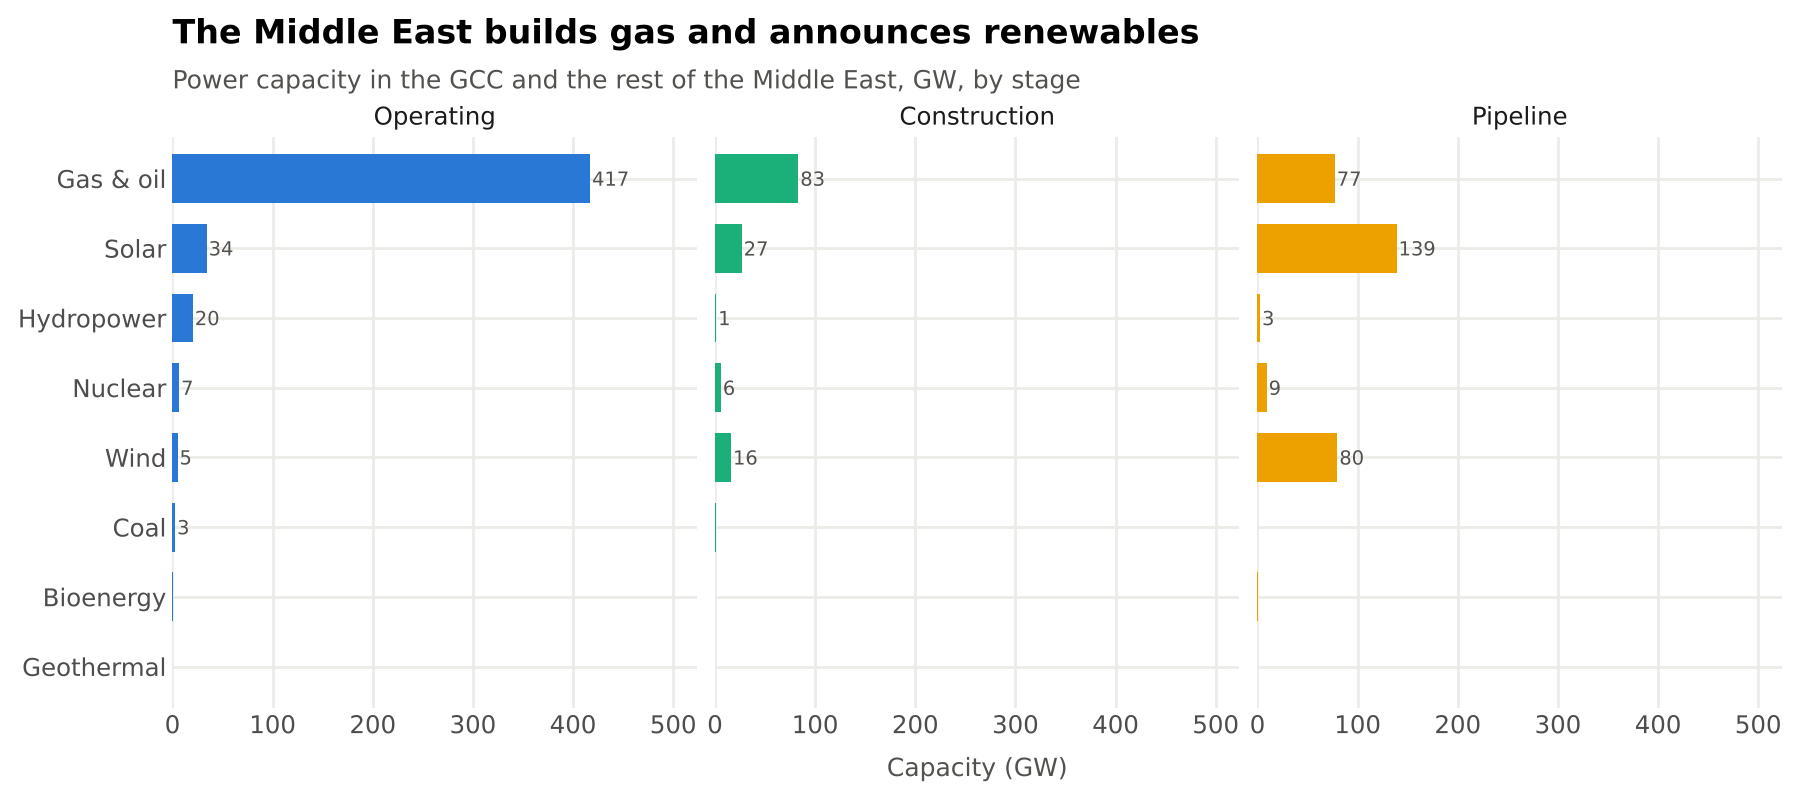

In [13]:
middle_east = units.loc[units["area"] != "Rest of world"]
me_stages = indicators.capacity_by_stage(middle_east, "technology")
plot = plots.plot_capacity_by_stage(
    me_stages,
    title="The Middle East builds gas and announces renewables",
    subtitle="Power capacity in the GCC and the rest of the Middle East, GW, by stage",
)
plots.save(plot, "middle_east_stages", 9, 4)
plot

The contrast between the three panels is the starting point of our question:

- **Operating**: the region runs on gas and oil (417 GW), far ahead of solar (34 GW).
- **Under construction**: gas still dominates (83 GW, including Iran and Iraq), ahead of
  solar (27 GW) and wind (16 GW).
- **Pipeline**: the picture reverses. Solar (139 GW) and wind (80 GW) dominate the announced
  projects, ahead of gas (77 GW).

The region announces an energy transition, but what it builds today is mostly gas.
Whether the renewable pipeline will be built is exactly the question of development risk.

# 4. How much of what is announced gets built?

In [14]:
world_rate = indicators.abandonment_rate(units.assign(scope="World"), "scope")
display(world_rate.style.format({"abandoned_gw": "{:,.0f}", "built_gw": "{:,.0f}",
                                 "outcome_gw": "{:,.0f}", "n_units": "{:,.0f}",
                                 "abandonment_rate": "{:.1%}"}))
WORLD_RATE = world_rate["abandonment_rate"].iloc[0]

,scope,abandoned_gw,built_gw,n_units,outcome_gw,abandonment_rate
0,World,"4,531","6,740","116,296","11,271",40.2%


**Worldwide, 40% of the capacity that reached an outcome was abandoned rather than built**:
about 4,500 GW abandoned against 6,700 GW built. That is roughly 2 GW abandoned,
for every 3 GW built

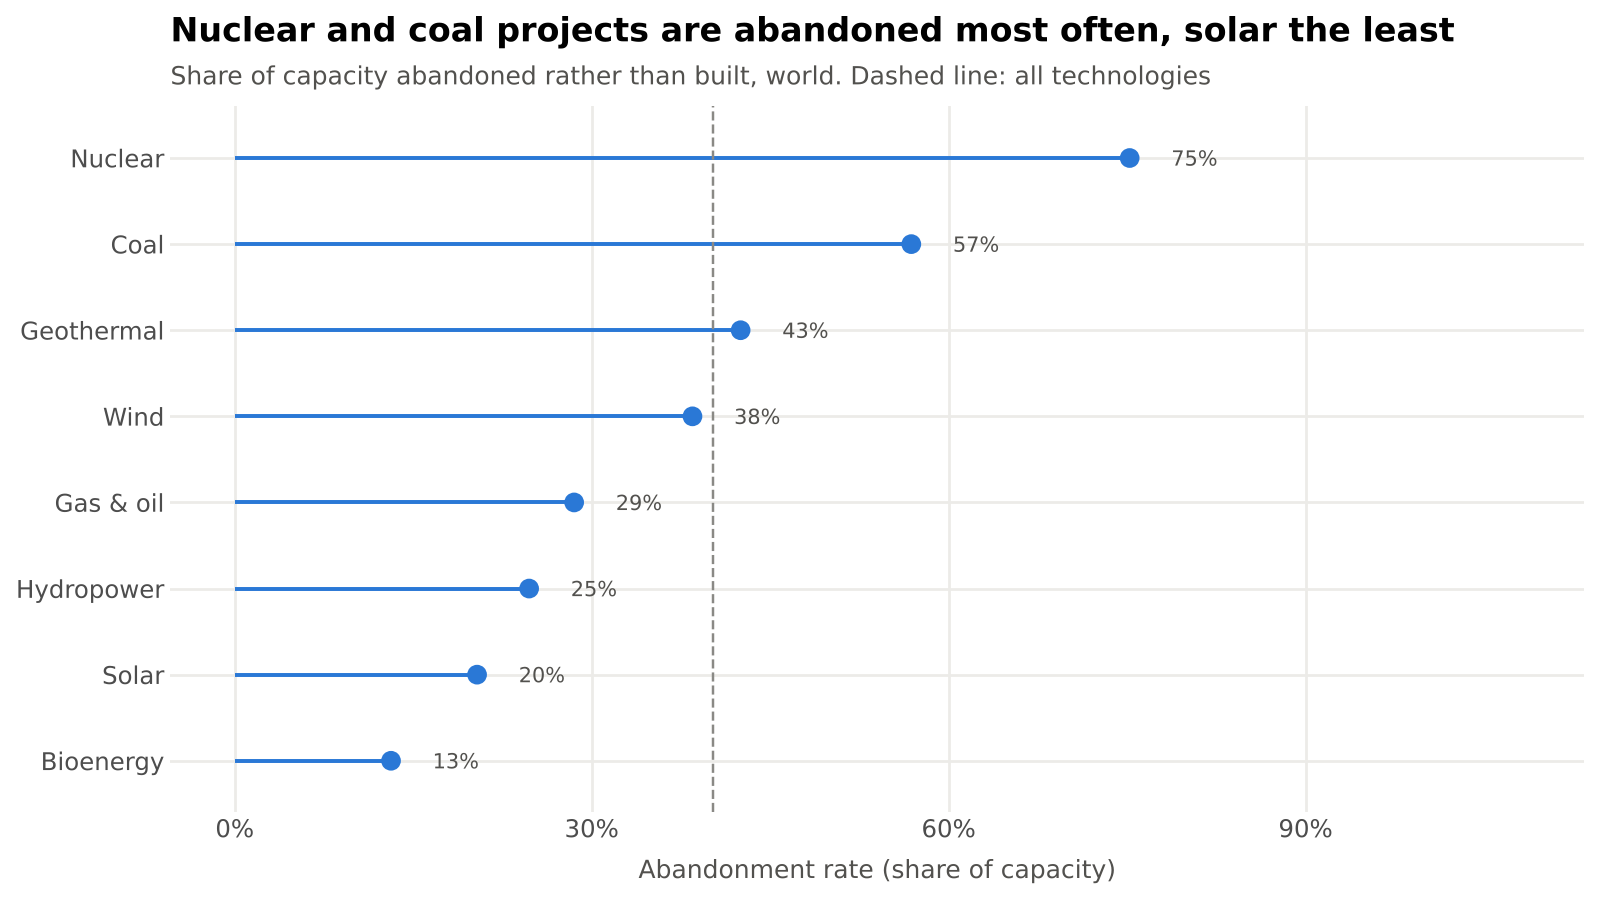

In [15]:
by_technology = indicators.abandonment_rate(units, "technology")
plot = plots.plot_rates(
    by_technology, "technology",
    title="Nuclear and coal projects are abandoned most often, solar the least",
    subtitle="Share of capacity abandoned rather than built, world. Dashed line: all technologies",
    reference=WORLD_RATE,
)
plots.save(plot, "rates_by_technology")
plot

The ranking is consistent with the size, complexity and political exposure of each
technology. Because abandoned projects are not dated, our data cannot tell *when* they were
abandoned; the explanations below are therefore plausible hypotheses, not results.

- **Nuclear (75%) and coal (57%)** are the riskiest. Nuclear projects are huge, slow and
  politically sensitive, and their rate is inflated by old cancellations (see 2.4). Coal
  projects were probably abandoned in large numbers as public and private lenders withdrew
  their support for coal over the last decade.
- **Wind (38%)** is riskier than **solar (20%)**. Wind projects, especially offshore, tend to
  face longer permitting, local opposition and, in recent years, cost increases.
- **Solar** is the safest technology to develop: projects are modular, quick to build and
  rarely contested.

### Robustness

Two choices can move the indicator in opposite directions. Excluding the statuses that
GEM only *infers* (no news for two to four years) gives a **lower bound**. Counting as built
only the plants already in operation, since projects under construction can still fail,
gives an **upper bound**.

In [16]:
robustness = pd.concat([
    indicators.robustness_checks(units.assign(scope="World"), "scope"),
    indicators.robustness_checks(units, "area"),
    indicators.robustness_checks(units, "technology"),
])
display(robustness.style.format("{:.0%}"))

definition,Excluding inferred statuses,Baseline,Excluding construction
World,32%,40%,48%
GCC,5%,14%,18%
Rest of Middle East,11%,23%,31%
Rest of world,33%,41%,48%
Bioenergy,4%,13%,14%
Coal,57%,57%,62%
Gas & oil,13%,29%,33%
Geothermal,13%,43%,49%
Hydropower,13%,25%,37%
Nuclear,63%,75%,85%


**The world rate lies between 32% and 48%** depending on the definition. The levels change with the definition
but the ranking of technologies and regions stays the same : in every case, nuclear and coal remain the riskiest
technologies, solar and bioenergy among the safest, and the GCC remains far below the rest
of the world. Our conclusions do not depend on these choices.

# 5. Where is development risk highest?

We now compute abandonment rates by country, keeping countries with at least 10 GW of
capacity in the outcome sample (74 countries), so that rates are not driven by one or two
projects.

In [17]:
countries = indicators.abandonment_rate(units, ["country", "iso3", "area"], min_gw=10)
plots.map_abandonment(countries)

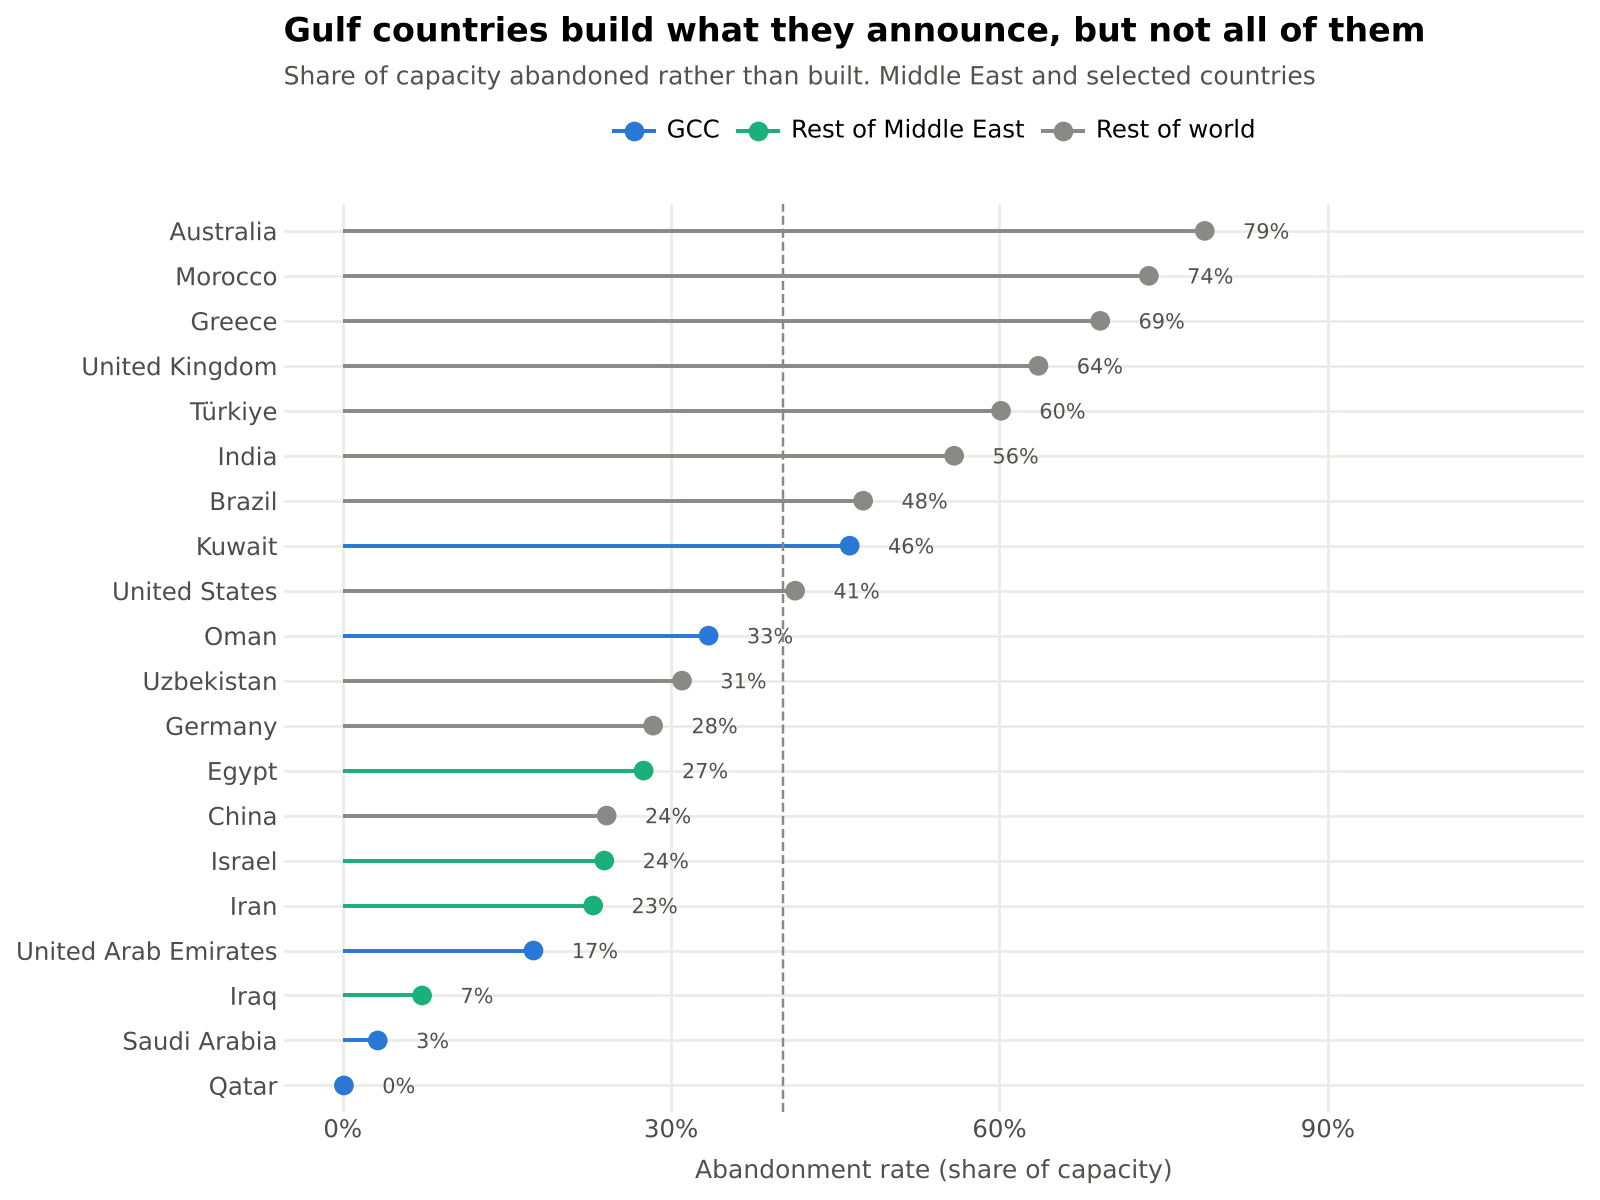

In [18]:
selection = ["India", "China", "United States", "United Kingdom", "Germany", "Australia",
             "Brazil", "Greece", "Türkiye", "Uzbekistan", "Morocco"]
shown = countries.loc[(countries["area"] != "Rest of world") | countries["country"].isin(selection)]
plot = plots.plot_rates(
    shown, "country", color="area", reference=WORLD_RATE, height=6,
    title="Gulf countries build what they announce, but not all of them",
    subtitle="Share of capacity abandoned rather than built. Middle East and selected countries",
)
plots.save(plot, "rates_by_country", 8, 6)
plot

Three patterns emerge.

**1. The Gulf stands out, but is not uniform.** Qatar (0%) and Saudi Arabia (3%) build
almost everything they announce. In these countries, a state buyer decides how
much capacity is needed, runs a tender, and signs a long-term contract with the winner: by
the time a project is public, its buyer and its price are already secured. The United Arab
Emirates (17%) and Oman (33%) are higher, and Kuwait (46%) is above the world average.

**2. High rates are not only a sign of fragility.** Myanmar, Zimbabwe or Ukraine have very
high rates, as expected. But so do the United Kingdom (64%), Denmark (78%), Sweden (77%) and
Australia (79%). In these open markets, many developers propose projects that compete for
the same grid connections, subsidies and buyers: most of them will not be built. A high
abandonment rate there reflects **who bears the development risk** (private developers,
before any contract) rather than a failing state.

**3. Measurement matters.** In open markets, projects enter public databases at an early
stage (permit applications), while in tender-based markets they often appear only once a
developer has been selected. Part of the Gulf's low rate therefore comes from *when*
projects become visible. This is a limit of the data, but it is also a feature of the
model: in the Gulf, the early, risky stage of development is carried out by the state.

What, then, is abandoned in the GCC? The ten largest abandoned projects are shown below.

In [19]:
gcc_abandoned = (
    units.loc[(units["area"] == "GCC") & units["abandoned"]]
    .groupby(["project", "country", "technology", "status"], as_index=False)["capacity_mw"].sum()
    .sort_values("capacity_mw", ascending=False)
    .head(10)
)
display(gcc_abandoned.style.format({"capacity_mw": "{:,.0f}"}).hide(axis="index"))

gcc_by_technology = indicators.abandonment_rate(units.loc[units["area"] == "GCC"], "technology")
display(gcc_by_technology[["technology", "abandoned_gw", "built_gw", "abandonment_rate"]]
        .style.format({"abandoned_gw": "{:,.1f}", "built_gw": "{:,.1f}",
                       "abandonment_rate": "{:.0%}"}).hide(axis="index"))

project,country,technology,status,capacity_mw
Scatec-Duqm Solar,Oman,Solar,shelved - inferred 2 y,"5,500"
North Kuwait Solar,Kuwait,Solar,shelved - inferred 2 y,"5,000"
Jubail (SWCC) power station,Saudi Arabia,Gas & oil,cancelled,"3,000"
Doha East power plant,Kuwait,Gas & oil,cancelled - inferred 4 y,"2,400"
Hassyan Clean-Coal Power Project,United Arab Emirates,Coal,cancelled,"2,400"
Taqa-KIZAD Green Ammonia solar farm,United Arab Emirates,Solar,shelved - inferred 2 y,"2,000"
Shuaiba South power plant,Kuwait,Gas & oil,cancelled - inferred 4 y,"1,800"
Al-Khairan power plant,Kuwait,Gas & oil,cancelled - inferred 4 y,"1,800"
Ras al-Khaimah power station,United Arab Emirates,Coal,cancelled,"1,800"
Al-Duqum Independent Water and Power Project,Oman,Coal,cancelled,"1,200"


technology,abandoned_gw,built_gw,abandonment_rate
Bioenergy,0.1,0.3,29%
Coal,6.7,0.0,100%
Gas & oil,9.1,156.6,6%
Hydropower,0.2,0.2,50%
Nuclear,0.0,5.7,0%
Solar,15.9,40.9,28%
Wind,0.6,3.1,17%


Abandonment in the Gulf has three identifiable causes:

- **Policy changes**: all coal projects (6.7 GW) were cancelled, including the Ras
  al-Khaimah and Ajman plants and the last units of Dubai's Hassyan plant, which was
  converted to gas (its gas units appear as operating in the data).
- **Stalled public-private partnerships in Kuwait**: several large gas plants procured by the
  Kuwait Authority for Partnership Projects (Al-Khairan, Doha East, Shuaiba South) were
  shelved. This explains Kuwait's 46%.
- **Projects tied to green hydrogen**: very large solar farms planned to power hydrogen or
  ammonia plants in Abu Dhabi and Oman, or announced without a buyer (North Kuwait Solar,
  Duqm) were shelved.

By contrast, gas projects, which feed the region's growing demand and are bought by
state utilities, have an abandonment rate of only 6%.

The map below shows each project of the Middle East that reached an outcome, with circles
proportional to its capacity.

In [20]:
plots.map_projects(middle_east, "Built and abandoned power projects in the Middle East")

### Country characteristics

Does development risk depend on a country's income or on the quality of its regulation?
We join the World Bank data and plot each country's abandonment rate against its
Regulatory Quality score.

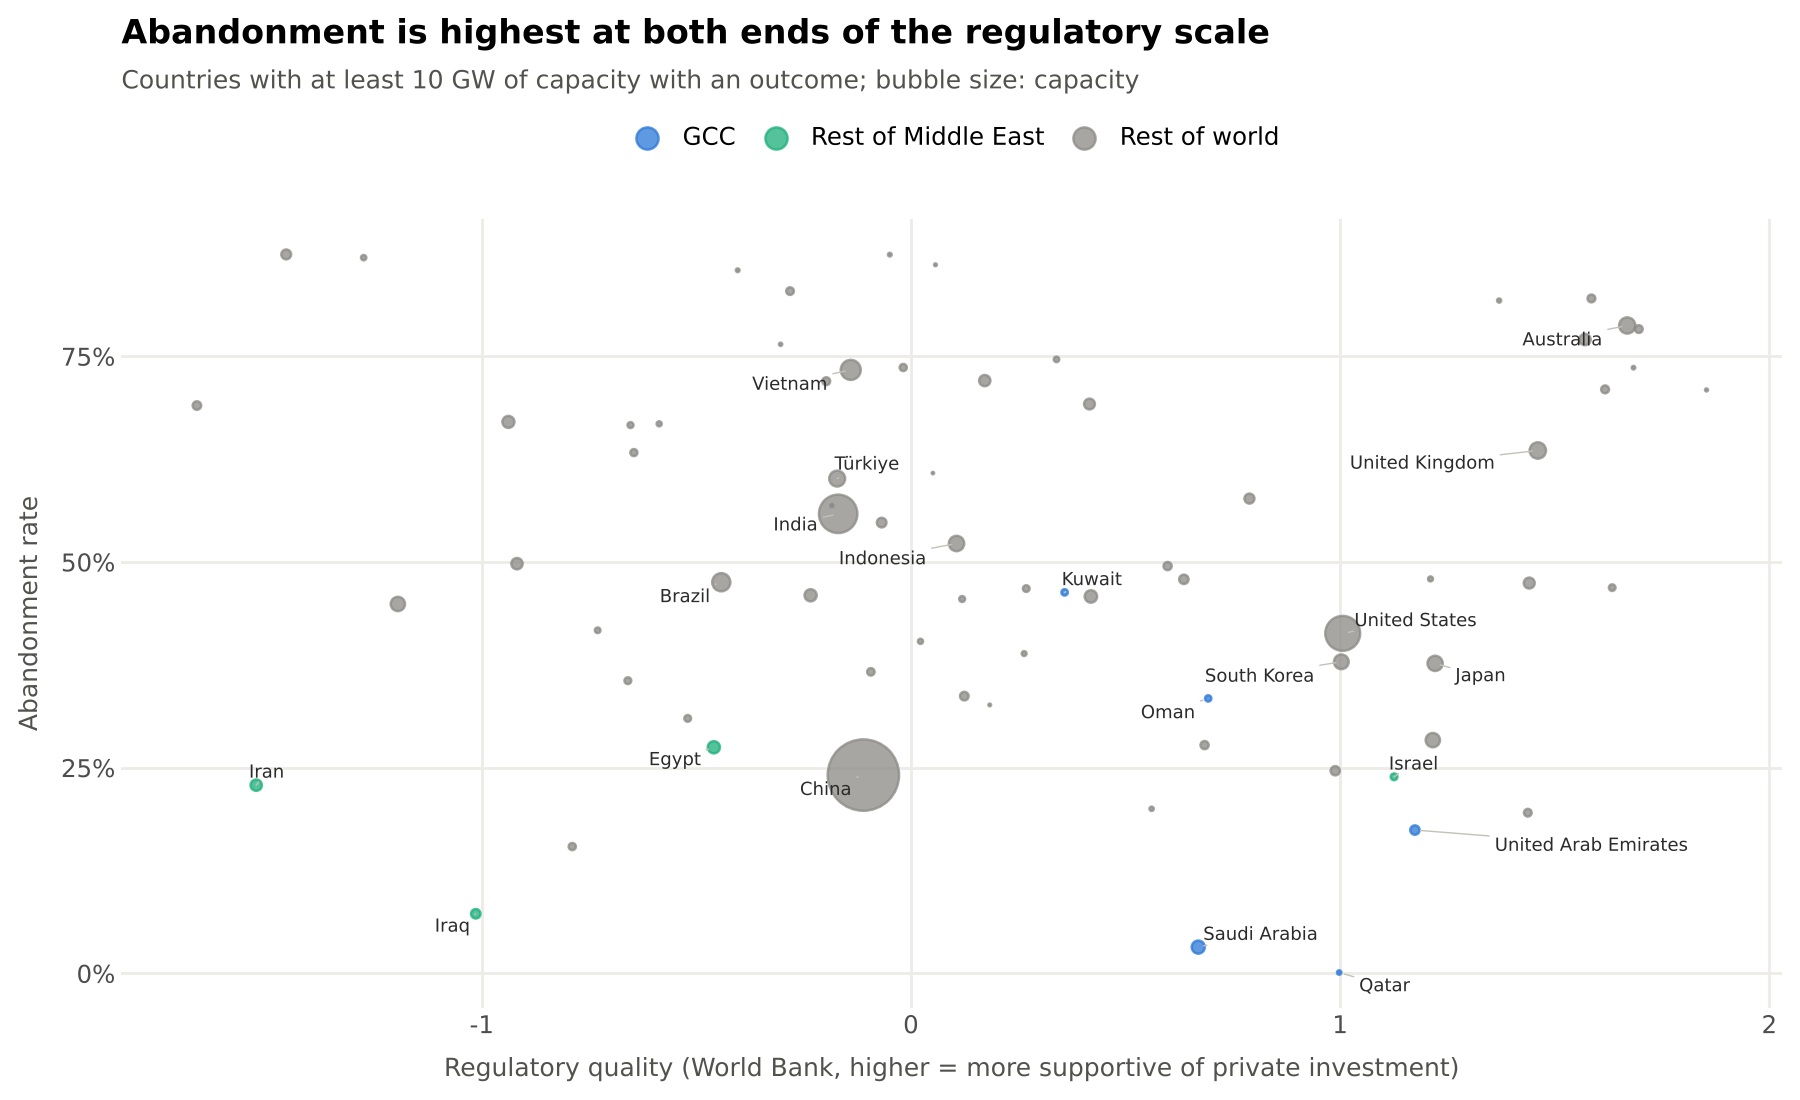

income_group,abandoned_gw,built_gw,n_units,outcome_gw,abandonment_rate
High income,"1,431","1,714","60,781","3,145",46%
Low income,46,32,613,79,59%
Lower middle income,"1,020",822,"9,102","1,842",55%
Upper middle income,"1,974","4,133","45,086","6,107",32%


Linear correlation between regulatory quality and abandonment rate: -0.03


regulation,outcome_gw,n_units,abandonment_rate
Weak (below -0.5),904,"4,646",49%
Average (-0.5 to 0.5),"7,507","60,667",37%
Good (0.5 to 1.2),"1,681","22,035",37%
Very good (above 1.2),"1,080","28,187",57%


In [21]:
countries_wb = countries.merge(wb, on="iso3", how="left")

plot = plots.plot_rate_vs_governance(
    countries_wb.dropna(subset=["regulatory_quality"]),
    title="Abandonment is highest at both ends of the regulatory scale",
    subtitle="Countries with at least 10 GW of capacity with an outcome; bubble size: capacity",
)
plots.save(plot, "rates_vs_regulation", 9, 5.5)
display(plot)

by_income = (
    units.loc[units["in_outcome_sample"]]
    .merge(wb[["iso3", "income_group"]], on="iso3", how="left")
    .pipe(indicators.abandonment_rate, "income_group")
)
display(by_income.style.format({"abandoned_gw": "{:,.0f}", "built_gw": "{:,.0f}",
                                "outcome_gw": "{:,.0f}", "n_units": "{:,.0f}",
                                "abandonment_rate": "{:.0%}"}).hide(axis="index"))
print("Linear correlation between regulatory quality and abandonment rate: "
      f"{countries_wb[['regulatory_quality', 'abandonment_rate']].corr().iloc[0, 1]:.2f}")

by_regulation = (
    units.merge(wb[["iso3", "regulatory_quality"]], on="iso3", how="left")
    .assign(regulation=lambda df: pd.cut(
        df["regulatory_quality"], indicators.REGULATION_BINS, labels=indicators.REGULATION_LABELS))
    .pipe(indicators.abandonment_rate, "regulation")
)
display(by_regulation[["regulation", "outcome_gw", "n_units", "abandonment_rate"]]
        .style.format({"outcome_gw": "{:,.0f}", "n_units": "{:,.0f}",
                       "abandonment_rate": "{:.0%}"}).hide(axis="index"))

**The relationship between regulation and development risk is U-shaped.** The linear
correlation is close to zero (-0.03 across 73 countries), but this does not mean there is
no relationship: a correlation cannot detect a U. The scatter plot and the table by class
show it. Countries with weak regulation (Myanmar, Zimbabwe, Libya) abandon 49% of their
capacity, and countries with the strongest regulation (Australia, Sweden, Denmark, the
United Kingdom) 57%, against 37% in between, where state-led systems such as Saudi Arabia,
Qatar or China sit. Section 6 confirms this U shape in the regression.

Income tells a similar story. Upper-middle-income countries have the lowest rate (32%),
because this group is dominated by China, where state-owned companies build most of the
capacity. High-income countries (46%) abandon more than them, and only slightly less than
lower-middle-income (55%) and low-income countries (59%).

This supports our reading of section 5: beyond the *quality* of the state, our results suggests 
that the way projects are selected matters more than the quality of regulation. Where a public 
planner or buyer selects projects before they are announced, few are abandoned; where many 
market, many projects die, however good the institutions.

# 6. Is it the market or the developer?

If the Gulf builds what it announces, is it because its developers are good at executing
projects, or because its market model removes most of the risk? To find out, we follow the
same companies outside their home country.

### 6.1 Developers and acquirers

We compute, for each of the 30 sponsors, its portfolio **abroad** by stage, and two ratios:

- the **pipeline ratio**: capacity in the pipeline or under construction, divided by
  capacity in operation. Above 1, a company mostly develops new projects (a **developer**);
  well below 1, it mostly owns plants that already run, often bought from others
  (an **acquirer** or operator).
- its **abandonment rate** abroad, on its share of each project.

In [22]:
profiles = indicators.sponsor_profiles(ownership, location="Abroad")
display(
    profiles[["sponsor_group", "origin", "portfolio_gw", "operating", "construction",
              "pipeline", "abandoned", "pipeline_ratio", "abandonment_rate"]]
    .style.format({c: "{:,.1f}" for c in ["portfolio_gw", "operating", "construction",
                                          "pipeline", "abandoned", "pipeline_ratio"]}
                  | {"abandonment_rate": "{:.0%}"}, na_rep="–")
    .hide(axis="index")
)

sponsor_group,origin,portfolio_gw,operating,construction,pipeline,abandoned,pipeline_ratio,abandonment_rate
ENGIE,Global peer,93.1,53.0,3.2,15.5,12.3,0.4,30%
RWE,Global peer,78.3,23.7,1.9,26.3,20.2,1.2,51%
Ørsted,Global peer,70.4,10.5,3.2,36.4,20.3,3.8,61%
Enel,Global peer,64.9,41.6,0.6,10.0,10.9,0.3,29%
EDF,Global peer,64.8,24.1,1.3,21.8,9.1,1.0,37%
Iberdrola,Global peer,50.4,10.0,1.1,23.2,11.6,2.4,56%
TotalEnergies,Global peer,49.7,7.8,1.8,36.9,2.8,5.0,33%
EDP,Global peer,38.0,18.2,0.7,12.7,3.8,0.7,23%
Masdar,Gulf,32.7,5.7,2.4,21.6,3.0,4.2,28%
ACWA Power,Gulf,27.2,8.5,2.3,10.1,5.9,1.5,37%


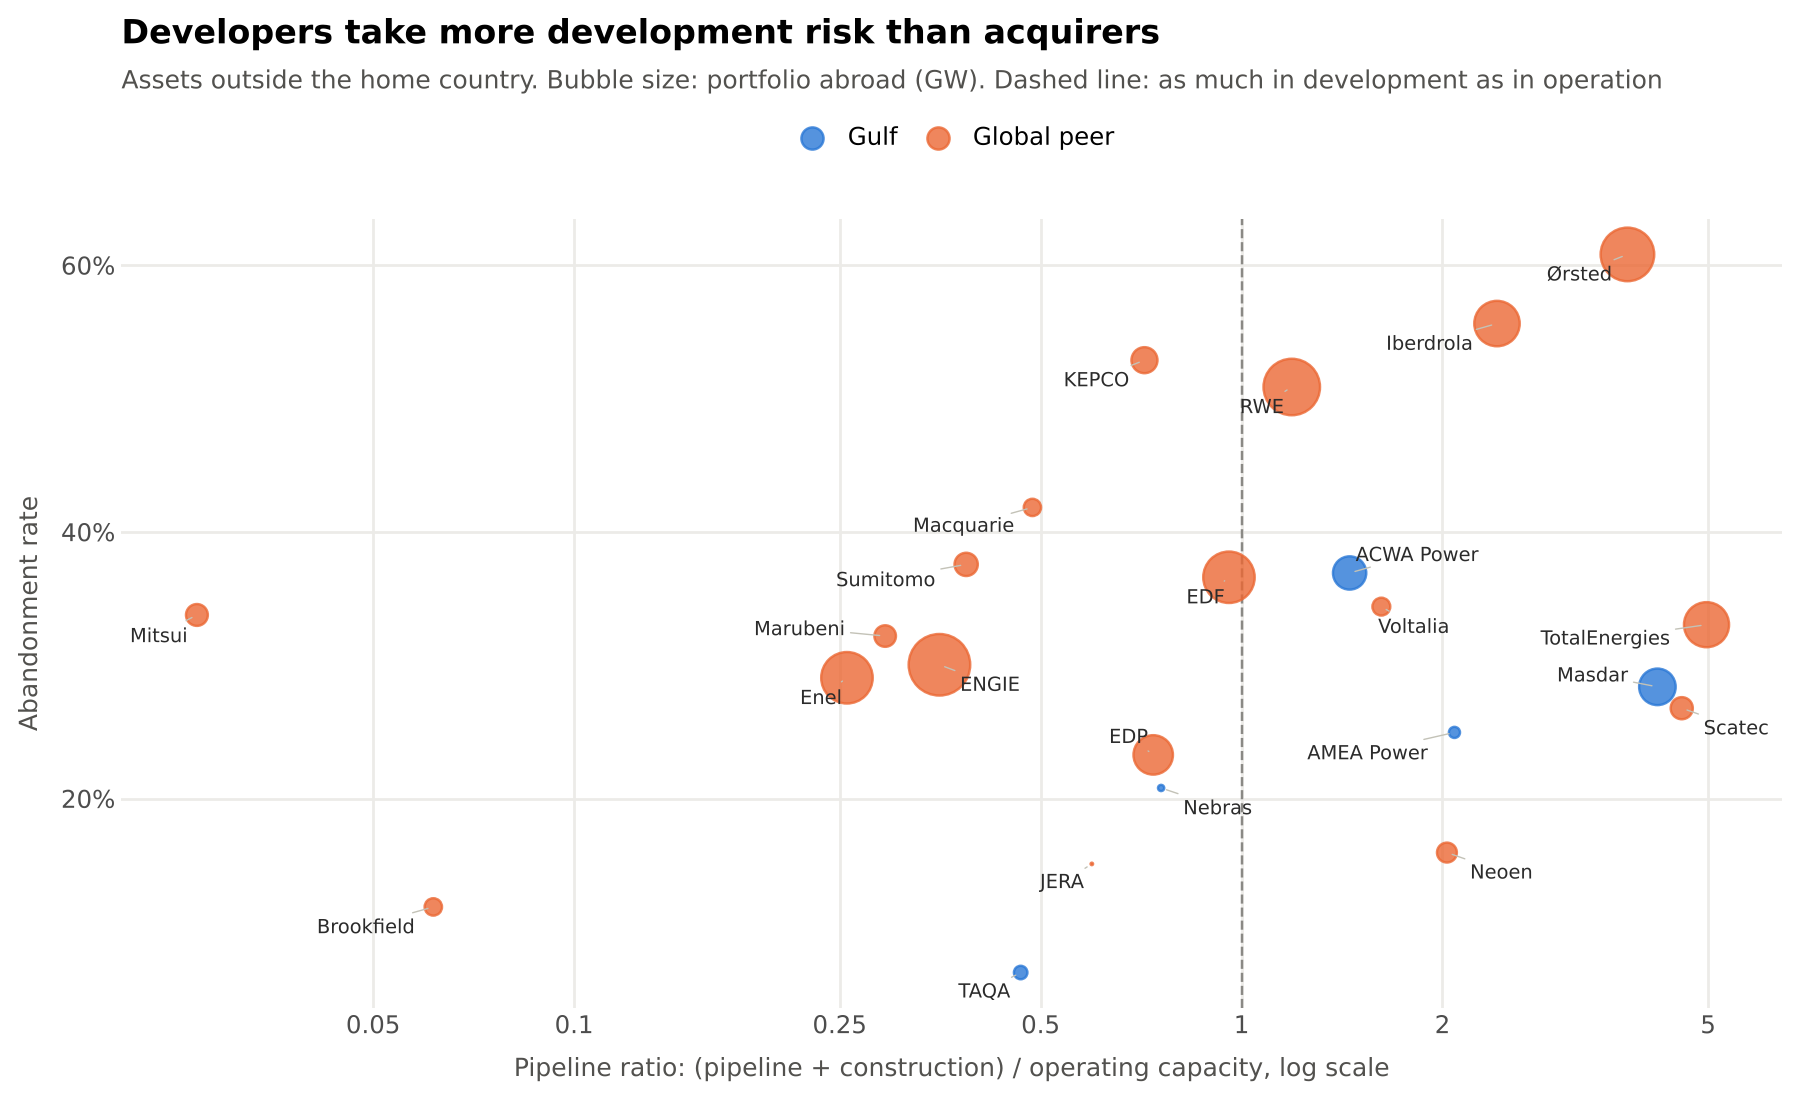

In [23]:
plot = plots.plot_sponsor_models(
    profiles,
    title="Developers take more development risk than acquirers",
    subtitle="Assets outside the home country. Bubble size: portfolio abroad (GW). "
             "Dashed line: as much in development as in operation",
)
plots.save(plot, "sponsor_models", 9, 5.5)
plot

The chart separates two business models.

- **Acquirers and operators**, on the left, own mostly operating plants: Brookfield
  (pipeline ratio 0.06), Mitsui (0.03), TAQA (0.5). Their abandonment rates are among the
  lowest (12% for Brookfield, 7% for TAQA): they buy assets once development risk is gone.
- **Developers**, on the right, have pipelines several times larger than their operating
  fleet: Masdar (4.2), Scatec (4.6), TotalEnergies (5.0), Ørsted (3.8). They carry the
  development risk themselves, and their abandonment rates are higher on average
  (61% for Ørsted, 56% for Iberdrola, hit by offshore wind cancellations).

**Gulf sponsors sit within these global models rather than apart from them.** Masdar
and ACWA Power behave like international renewable developers, with abandonment rates
abroad (28% and 37%) close to their peers. TAQA and Nebras look like acquirers.

One caveat on Masdar: by attaching Terna Energy and Saeta Yield to it (section 2.6), we also
attribute to Masdar the projects these companies abandoned before Masdar bought them.
Without them, Masdar's rate abroad falls from 28% to 22%, and that of all Gulf sponsors
abroad from 34% to 33%: the conclusions below do not change.

### 6.2 The same developers at home and abroad

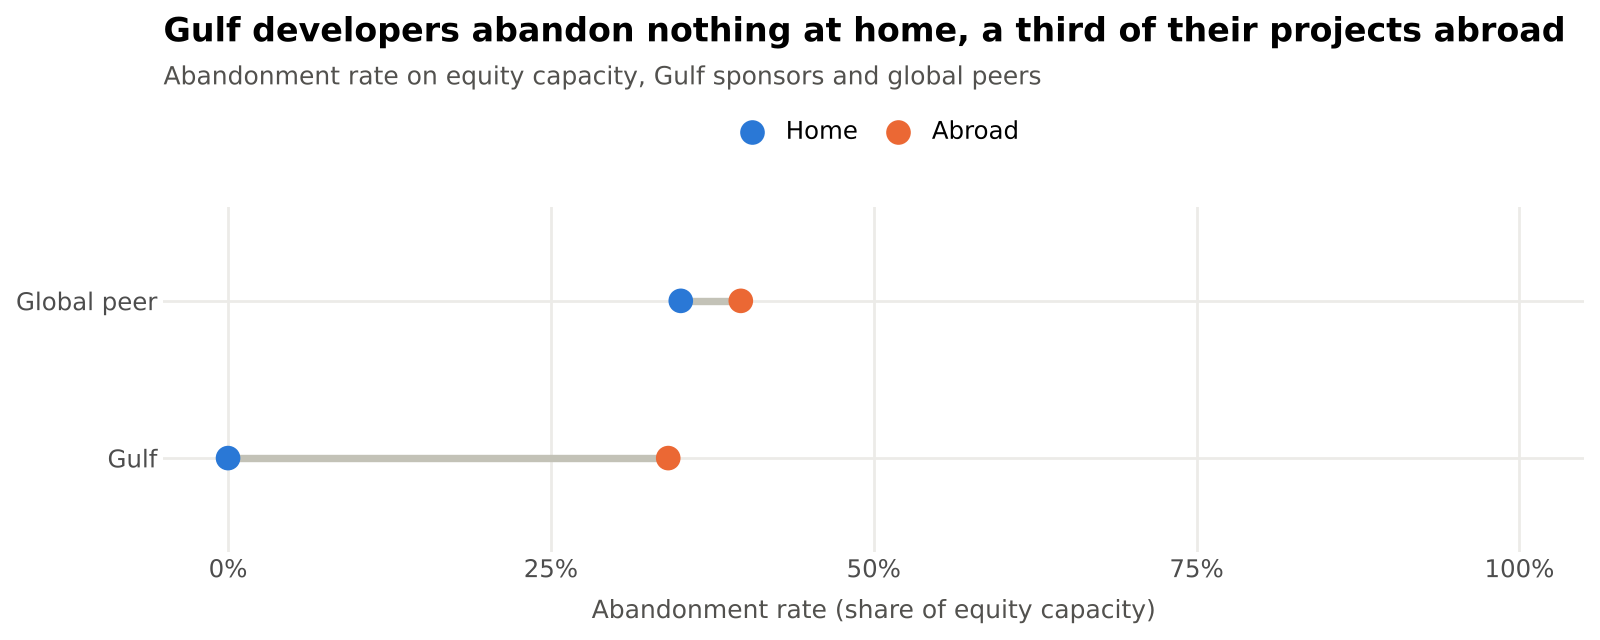

In [24]:
home_abroad = indicators.home_vs_abroad(ownership, by="origin").rename(columns={"origin": "group"})
plot = plots.plot_home_abroad(
    home_abroad,
    title="Gulf developers abandon nothing at home, a third of their projects abroad",
    subtitle="Abandonment rate on equity capacity, Gulf sponsors and global peers",
)
plots.save(plot, "home_vs_abroad", 8, 3.2)
display(plot)

gulf_detail = (
    indicators.home_vs_abroad(ownership, by="sponsor_group")
    .loc[lambda df: df["sponsor_group"].isin(["ACWA Power", "Masdar", "TAQA", "Nebras"])]
    .pivot(index="sponsor_group", columns="location", values=["abandonment_rate", "outcome_gw"])
)
display(gulf_detail.style.format("{:.2f}"))

This is the clearest result of the project. **At home, Gulf sponsors abandoned none of the
45 GW of capacity that reached an outcome. Abroad, they abandoned 34%**, almost as much as
global peers abroad (40%). The same holds company by company: ACWA Power goes from 0% at home
to 37% abroad, Masdar from 0% to 28%.

Global peers show a much smaller gap between home and abroad (35% and 40%), because their
home markets (Europe, Japan, Korea) are themselves open, competitive markets.

At home, Gulf developers bid in state
tenders: when they win, the project already has a buyer, a price and the government's
support. Abroad, they face the same permits, grid constraints and political risks as
everyone else. **For an investor, a Gulf developer's near-perfect record at home says little
about its projects abroad.**

The measurement issue of section 5 applies here too. At home, Gulf sponsors appear in the
data only once they have won a tender, so their 0% is partly mechanical. Our data cannot
fully separate two explanations that point the same way: the state-tender model itself,
and the late stage at which projects become visible in such markets. Either way, the
risk that Gulf developers avoid at home is carried by the state, not by them.

### 6.3 A logistic regression

The comparisons above do not hold everything else equal: Gulf sponsors abroad build mostly
solar, in emerging countries, which may have their own risk. We therefore estimate a
logistic regression on the units of the outcome sample:

$$\Pr(\text{abandoned}_i = 1) = \Lambda(\beta_0 + \beta_1 \text{technology}_i
+ \beta_2 \log(\text{capacity}_i) + \beta_3 \text{country}_i
+ \beta_4 \text{owner}_i)$$

where $\Lambda$ is the logistic function. We report **odds ratios**: a ratio of 2 means
that the odds of abandonment are twice as high as for the reference category, everything
else being equal. Four choices matter:

- **Weights.** Our descriptive rates are weighted by capacity. Counted in units, the
  sample is dominated by small solar farms (two thirds of the units), which are rarely
  abandoned. The main models therefore **weight each unit by its capacity**, so that they
  explain the same thing as our charts. The unweighted model is shown as a check.
- **Owners.** The variable *owner* distinguishes Gulf sponsors abroad, global peers, other
  known owners (reference) and **units with no known owner** (58% of the units, mostly
  small projects), which form their own category so as not to bias the reference.
- **Gulf sponsors at home.** None of their 102 units at home was abandoned. A logit cannot
  estimate an effect for a category without a single failure (perfect prediction), so these
  units are left out of the regression; their 0% is the descriptive result of 6.2. The
  model therefore tests whether Gulf sponsors *abroad* differ from other owners.
- **Standard errors** are clustered by country, because projects in the same country share
  the same regulations and grid. Note that the GCC effect is then identified by only six
  countries, so its p-value should be read with caution. statsmodels also warns that
  clustered errors are not fully supported with weights; the unweighted model, where this
  issue does not arise, gives the same conclusions on owners.

We estimate model A, which describes the host country by its region only (GCC, rest of the
Middle East, rest of the world), and model B, which adds the World Bank income group and
Regulatory Quality score, with a squared term to capture the U shape seen in section 5.

In [25]:
model_data = model.model_table(units, ownership, wb)

formula_a = ('abandoned ~ C(technology, Treatment("Solar")) + log_capacity'
             ' + C(area, Treatment("Rest of world")) + C(sponsor, Treatment("Other owner"))')
formula_b = formula_a + (' + C(income_group, Treatment("High income"))'
                         ' + regulatory_quality + I(regulatory_quality ** 2)')

models = {
    "A, unweighted": model.fit_logit(model_data, formula_a, weighted=False),
    "A": model.fit_logit(model_data, formula_a),
    "B": model.fit_logit(model_data, formula_b),
}
comparison = model.compare_models(models)
display(comparison.style.format("{:.2f}", subset=comparison.columns[1:], na_rep="–")
        .hide(axis="index"))
display(model.model_summary(models).style.format({"units": "{:,.0f}", "pseudo_r2": "{:.2f}"}))

label,"odds_ratio (A, unweighted)","p_value (A, unweighted)",odds_ratio (A),p_value (A),odds_ratio (B),p_value (B)
Technology: Bioenergy,0.90,0.66,1.28,0.38,1.11,0.70
Technology: Coal,2.68,0.01,3.70,0.00,4.40,0.00
Technology: Gas & oil,0.92,0.88,1.45,0.50,1.30,0.60
Technology: Geothermal,2.28,0.02,4.93,0.00,3.89,0.00
Technology: Hydropower,1.31,0.49,0.47,0.05,0.48,0.08
Technology: Nuclear,6.16,0.00,6.29,0.00,6.25,0.00
Technology: Wind,2.23,0.01,2.10,0.00,1.79,0.01
Region: GCC,0.33,0.01,0.35,0.03,0.28,0.01
Region: Rest of Middle East,0.87,0.53,0.52,0.02,0.32,0.00
Owner: Global peer,0.91,0.79,1.13,0.75,0.87,0.63


,units,pseudo_r2
"A, unweighted","116,194",0.23
A,"116,194",0.14
B,"115,433",0.18


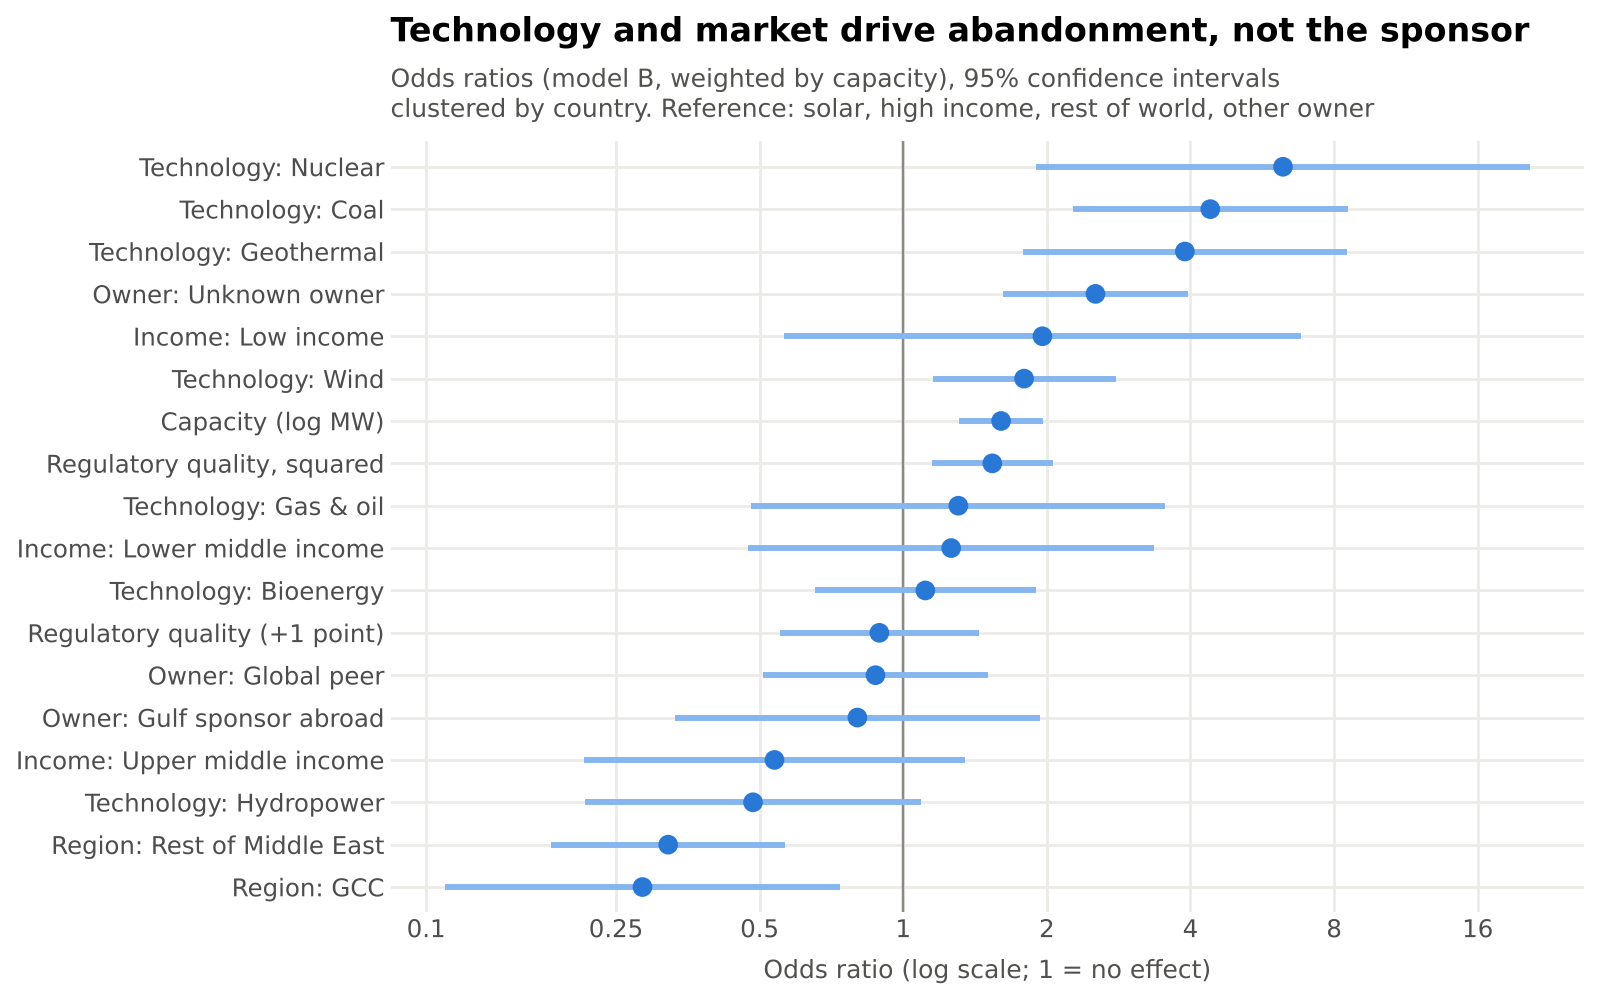

In [26]:
plot = plots.plot_odds_ratios(
    model.readable_labels(model.odds_ratios(models["B"])),
    title="Technology and market drive abandonment, not the sponsor",
    subtitle="Odds ratios (model B, weighted by capacity), 95% confidence intervals\n"
             "clustered by country. Reference: solar, high income, rest of world, other owner",
)
plots.save(plot, "odds_ratios", 8, 5.5)
plot

The weighted models confirm the descriptive analysis:

- **Technology** has the largest effect. All else equal, the odds of abandonment are about
  6 times higher for nuclear, 3.7 times for coal and 2.1 times for wind than for solar
  (model A).
- **Size** matters: each doubling of capacity raises the odds of abandonment by about 40%
  (odds ratio of 1.6 per unit of log capacity).
- **Being in the GCC** divides the odds by about three (odds ratio 0.35 in model A, 0.28 in
  model B), all else equal, with the caveat on six clusters noted above.
- **The sponsor does not matter**: Gulf sponsors abroad (0.98) and global peers (1.13) have
  odds ratios close to 1 and far from significant, in all three models. Once technology,
  size and location are accounted for, projects led by large international companies are
  abandoned as often as those of other known owners.
- **Large projects with no known owner are abandoned more often** (2.4 in model A). These
  are typically projects announced before any developer was selected, such as some
  government-announced solar programmes: this is consistent with our reading that
  development risk is highest when no one has yet committed to build.

Model B adds country characteristics. **The squared regulatory quality term is positive and
significant (1.54, p < 0.01)**: the regression confirms the U shape of section 5, with more
abandonment at both ends of the regulatory scale. Income groups are not significant once
regulation is accounted for. The GCC effect remains: Gulf countries abandon less than their
income and regulation would predict, which points again to their procurement model.

The unweighted model, which mainly describes small units, gives the same message on
technology, size, the GCC and sponsors. It differs on owners without a known name, which are
mostly small solar farms and rarely abandoned when counted in units.

These are associations, not causal effects. Units of the same project are not fully
independent (116,296 units belong to about 100,000 projects); clustering by country
partly addresses this, and a project-level model would be a natural extension.

# 7. Conclusion

**Which power projects actually get built, and why?**

About 60% of the power capacity that reached an outcome since 2010 was built, and 40% was
abandoned. Development risk depends first on the **technology**: solar projects rarely
fail, nuclear and coal projects often do. It depends next on the **market**: in the Gulf
states, where a single public buyer tenders projects and signs long-term contracts, almost
everything that becomes public gets built. In open markets, rich or poor, many projects
compete and most of them die before construction. The relationship with the quality of
regulation is U-shaped: abandonment is highest both where institutions are weak and in the
most open, best-regulated markets. Finally, it depends little on the
**developer**: the same Gulf companies that build all of their projects at home abandon a
third of them abroad, like their Western and Asian peers.

**What this means for infrastructure investors.**

- A pipeline must be valued market by market: a gigawatt announced in Saudi Arabia and a
  gigawatt announced in the United Kingdom do not carry the same probability of being built.
- A developer's track record in a protected home market does not transfer abroad. Investors
  partnering with Gulf developers in third countries take ordinary development risk.
- Acquirers such as Brookfield or TAQA avoid most development risk by buying operating
  plants: this is the trade-off between core infrastructure, with lower risk, and
  value-add strategies, which pay for taking development risk.
- In the Middle East, the large renewable pipeline will be credible where it goes through
  state tenders; projects announced without a buyer, such as solar farms for green hydrogen,
  are the most fragile.

**Limits.**

- The tracker is a snapshot: we cannot follow projects from announcement to completion,
  and we approximate outcomes with a 2010 cut-off.
- Abandoned projects are not dated, while built projects are restricted to those built
  since 2010: old cancellations are compared with recent constructions, which inflates the
  rates of technologies such as nuclear. The rates are orders of magnitude, between 32% and
  48% worldwide depending on the definition.
- Projects enter the data at different stages depending on the market, which partly
  explains the low rates of tender-based markets, and the 0% of Gulf developers at home.
- Owners are unknown for many small solar projects, and ownership shares are missing for
  about a quarter of renewable ownership records (capacity is then split equally).
  Our sponsor dictionary covers 30 companies.
- Small installations below GEM's thresholds are not covered.

**Extensions.** Comparing two releases of the tracker would allow a true cohort analysis
(which projects moved from announced to construction in a year). Adding information on
offtake contracts (who buys the electricity) would test directly the role of the
single-buyer model.

---

### References

- Global Energy Monitor, *Global Integrated Power Tracker*, September 2026 release. CC BY 4.0.
- World Bank, *World Development Indicators* and *Worldwide Governance Indicators*, via the
  World Bank API v2.
- Kaufmann, D. and Kraay, A., *The Worldwide Governance Indicators: Methodology and 2024 Update*.
- Galiana, L., *Python pour la data science*, ENSAE course, https://pythonds.linogaliana.fr